### Домашнє завдання: Пониження розмірностей для Аналізу Портретів Клієнтів

#### Контекст
В цьому ДЗ ми попрацюємо з методами пониження розмірності на наборі даних для задачі аналізу портретів клієнтів (Customer Personality Analysis). **В попередньому ДЗ ми працювали з цими даними використовуючи кластеризацію, зараз використаємо кластеризацію і візуалізауємо результати з різними методами.**

Customer Personality Analysis - це аналіз різних сегментів клієнтів компанії. Цей аналіз дозволяє бізнесу краще розуміти своїх клієнтів і полегшує процес адаптації продуктів під конкретні потреби, поведінку та інтереси різних типів клієнтів.

Аналіз портретів клієнтів допомагає бізнесу змінювати свій продукт на основі цільової аудиторії, розділеної на різні сегменти. Наприклад, замість того, щоб витрачати гроші на маркетинг нового продукту для всіх клієнтів у базі даних компанії, бізнес може проаналізувати, який сегмент клієнтів найімовірніше придбає продукт, і потім зосередити маркетингові зусилля лише на цьому сегменті.

#### Вхідні дані
Вам надано набір даних з такими атрибутами:

**Характеристики користувачів:**
- `ID`: Унікальний ідентифікатор клієнта
- `Year_Birth`: Рік народження клієнта
- `Education`: Рівень освіти клієнта
- `Marital_Status`: Сімейний стан клієнта
- `Income`: Річний дохід домогосподарства клієнта
- `Kidhome`: Кількість дітей у домогосподарстві клієнта
- `Teenhome`: Кількість підлітків у домогосподарстві клієнта
- `Dt_Customer`: Дата реєстрації клієнта у компанії
- `Recency`: Кількість днів з моменту останньої покупки клієнта
- `Complain`: 1, якщо клієнт скаржився за останні 2 роки, 0 - якщо ні

**Продукти:**
- `MntWines`: Сума, витрачена на вино за останні 2 роки
- `MntFruits`: Сума, витрачена на фрукти за останні 2 роки
- `MntMeatProducts`: Сума, витрачена на м'ясні продукти за останні 2 роки
- `MntFishProducts`: Сума, витрачена на рибні продукти за останні 2 роки
- `MntSweetProducts`: Сума, витрачена на солодощі за останні 2 роки
- `MntGoldProds`: Сума, витрачена на золото за останні 2 роки

**Акції:**
- `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
- `AcceptedCmp1`: 1, якщо клієнт прийняв пропозицію у першій кампанії, 0 - якщо ні
- `AcceptedCmp2`: 1, якщо клієнт прийняв пропозицію у другій кампанії, 0 - якщо ні
- `AcceptedCmp3`: 1, якщо клієнт прийняв пропозицію у третій кампанії, 0 - якщо ні
- `AcceptedCmp4`: 1, якщо клієнт прийняв пропозицію у четвертій кампанії, 0 - якщо ні
- `AcceptedCmp5`: 1, якщо клієнт прийняв пропозицію у п'ятій кампанії, 0 - якщо ні
- `Response`: 1, якщо клієнт прийняв пропозицію в останній кампанії, 0 - якщо ні

**Взаємодія з компанією:**
- `NumWebPurchases`: Кількість покупок, зроблених через вебсайт компанії
- `NumCatalogPurchases`: Кількість покупок, зроблених за каталогом
- `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
- `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць


Для початку, запустіть код нижче. Всі ці кроки ми робили в попередньому ДЗ і для того, щоб результати кластеризації у нас були схожими, потрібно аби передобробка була однаковою.

In [1]:
import pandas as pd
import os
from google.colab import drive

drive.mount('/content/drive')

# 1. Завантаження даних
# df = pd.read_csv('marketing_campaign.csv', sep='\t')
data_dir = '/content/drive/MyDrive/ML1/data/'
print(os.listdir(data_dir))
df = pd.read_csv(data_dir + 'marketing_campaign.csv', sep='\t')
print(df.shape)

# 2. Обробка пропущених значень
df['Income_not_filled'] = df.Income.isna()
df.Income = df.Income.fillna(-1)

# 3. Обробка дати реєстрації
df.Dt_Customer = pd.to_datetime(df.Dt_Customer, format='%d-%m-%Y')
today = df.Dt_Customer.max()
df['days_lifetime'] = (today - df.Dt_Customer).dt.days
df['years_customer'] = df.Year_Birth.apply(lambda x: today.year - x)

# 4. Категоризація рівня освіти
df_education = pd.get_dummies(df.Education, prefix='education').astype(int)
df = pd.concat([df, df_education], axis=1)

# 5. Очищення сімейного стану
marital_status_map = {'Alone': 'Single', 'Absurd': 'Else', 'YOLO': 'Else'}
df['Marital_Status_clean'] = df.Marital_Status.map(marital_status_map)
df_ms = pd.get_dummies(df.Marital_Status_clean, prefix='marital').astype(int)
df = pd.concat([df, df_ms], axis=1)

# 6. Форматування доходу і видалення викиду
df.Income = df.Income.astype(int)
df = df[df.Income != 666666]

# 7. Створення фінального набору даних
X = df.drop(['ID', 'Dt_Customer', 'Education', 'Marital_Status', 'Marital_Status_clean'], axis=1)
X.reset_index(drop=True, inplace=True)

Mounted at /content/drive
['credit', 'cars.csv', 'medical-charges.csv', 'workdata', 'kaggle_data', 'estimation_of_obesity_levels_based_on_eating_habits_and_physical.csv', 'regression_data.csv', 'customer_segmentation_train.csv', 'bank-additional-full.csv', 'bank_additional_full.xlsx', 'marketing_campaign.csv']
(2240, 29)


In [2]:
feats = ['Income', 'Recency', 'NumStorePurchases', 'NumDealsPurchases',
         'days_lifetime', 'years_customer', 'NumWebVisitsMonth']

print('X:', X.shape)
print('Income == -1:', (X['Income'] == -1).sum())
print('years_customer, 4 найбільші:', sorted(X['years_customer'])[-4:])
print('Marital_Status_clean:', df['Marital_Status_clean'].value_counts(dropna=False).to_dict())
print('повних дублікатів у X:', X.duplicated().sum())
print(X[feats].describe().round(1).T[['mean', 'std', 'min', 'max']])

X: (2239, 35)
Income == -1: 24
years_customer, 4 найбільші: [74, 114, 115, 121]
Marital_Status_clean: {nan: 2232, 'Else': 4, 'Single': 3}
повних дублікатів у X: 182
                      mean      std   min       max
Income             51412.8  22069.6  -1.0  162397.0
Recency               49.1     29.0   0.0      99.0
NumStorePurchases      5.8      3.3   0.0      13.0
NumDealsPurchases      2.3      1.9   0.0      15.0
days_lifetime        353.6    202.2   0.0     699.0
years_customer        45.2     12.0  18.0     121.0
NumWebVisitsMonth      5.3      2.4   0.0      20.0


In [8]:
# МОЄ РІШЕННЯ: те саме очищення, що в ДЗ модуля 3.
# 1. Видаляю 24 клієнти без доходу. Викладач заповнив їх маркером -1, а -1 це не дохід: такі клієнти автоматично стали б "найбіднішими".
#    Рядки знаходжу за прапорцем Income_not_filled, а не за -1.
# 2. Видаляю повні дублікати: KMeans зважує точку за кратністю.
# 3. Видаляю Income за межею Тьюкі (Q3 + 1.5 * IQR).
# 4. Видаляю Year_Birth < 1940: вік понад 110 років неможливий, а years_customer у цьому ДЗ іде прямо в кластеризацію.

print('після клітинки викладача:', X.shape)

X_clean = X.copy()
# X побудований з df після кроку 6, тому позиції рядків збігаються
X_clean['Marital_Status'] = df['Marital_Status'].values
X_clean = X_clean.drop(columns=[c for c in X_clean.columns if c.startswith('marital_')])
X_clean['HasPartner'] = X_clean['Marital_Status'].isin(['Married', 'Together']).astype(int)

X_clean = X_clean[~X_clean['Income_not_filled']].reset_index(drop=True)
print('без пропущених доходів:', X_clean.shape)

X_clean = X_clean[~X_clean['Marital_Status'].isin(['Absurd', 'YOLO'])].reset_index(drop=True)
print('без Absurd і YOLO:', X_clean.shape)

# Дублікати шукаю, поки є текстовий Marital_Status: HasPartner не розрізняє Married і Together, і два різні клієнти могли б виглядати однаково
dup = X_clean.duplicated()
print('повних дублікатів:', dup.sum())
X_clean = X_clean[~dup].reset_index(drop=True)

q1, q3 = X_clean['Income'].quantile([0.25, 0.75])
hi_fence = q3 + 1.5 * (q3 - q1)
print('межа Тьюкі для Income: %.1f, за нею %d рядків'
      % (hi_fence, (X_clean['Income'] > hi_fence).sum()))
print('Year_Birth < 1940:', (X_clean['Year_Birth'] < 1940).sum())

X_clean = X_clean[(X_clean['Income'] <= hi_fence)
                  & (X_clean['Year_Birth'] >= 1940)].reset_index(drop=True)
X_clean = X_clean.drop(columns=['Marital_Status'])

print('після очищення:', X_clean.shape)
print('HasPartner:', X_clean['HasPartner'].value_counts().to_dict())

після клітинки викладача: (2239, 35)
без пропущених доходів: (2215, 35)
без Absurd і YOLO: (2211, 35)
повних дублікатів: 182
межа Тьюкі для Income: 117993.5, за нею 7 рядків
Year_Birth < 1940: 3
після очищення: (2019, 34)
HasPartner: {1: 1294, 0: 725}


### Завдання 1: Виконання кластеризації та пониження розмірності для візуалізації результатів

Ваше завдання — провести кластеризацію клієнтів та візуалізувати результати кластеризації, використовуючи метод головних компонент (PCA) для пониження розмірності даних.

#### Інструкції:

1. **Вибір ключових характеристик:**
   Давайте обмежимось тільки наступними хараткеристиками для кластеризації цього разу:
   - `Income`: Річний дохід домогосподарства клієнта
   - `Recency`: Кількість днів з моменту останньої покупки клієнта
   - `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
   - `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
   - `days_lifetime`: Кількість днів з моменту реєстрації клієнта у компанії
   - `years_customer`: Вік клієнта
   - `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць
   Відберіть в наборі даних `X` лише ці характеристики.

2. **Стандартизація даних:**
   Використайте метод `StandardScaler` для стандартизації значень обраних характеристик.
   
   **Чому не MinMaxScaler:**
   - Для PCA краще використовувати StandardScaler, бо він вирівнює дисперсію ознак, на відміну від MinMaxScaler, що просто масштабує значення без врахування варіації.

   - Для K-Means також краще використовувати StandardScaler, бо алгоритм чутливий до масштабів: фічі з більшими значеннями сильніше впливають на обчислення відстаней, що може спотворити кластери.

3. **Кластеризація:**
   Проведіть кластеризацію клієнтів, використовуючи метод `KMeans` з трьома кластерами.

4. **Пониження розмірності:**
   Використайте метод головних компонент (PCA) для пониження розмірності даних до трьох компонент.

5. **Візуалізація результатів:**
   Використовуючи plolty express побудуйте 3D-графік розподілу клієнтів у просторі трьох головних компонент, де кольором позначено кластери.

6. **Опишіть, що спостерігаєте:**
   Чи кластеризація чітко розділила дані?

Далі ми детальніше проінтерпретуємо результати візуалізації і пониження розмірностей.

In [9]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import plotly.express as px

feats = ['Income', 'Recency', 'NumStorePurchases', 'NumDealsPurchases',
         'days_lifetime', 'years_customer', 'NumWebVisitsMonth']

X_dr = X_clean[feats].copy()
print('X_dr:', X_dr.shape)

# Скейлер вчиться на тих самих рядках, які кластеризую
scaler_dr = StandardScaler()
X_dr_scaled = scaler_dr.fit_transform(X_dr)
print('найбільший |z| по колонках:',
      dict(zip(feats, np.abs(X_dr_scaled).max(axis=0).round(2))))

X_dr: (2019, 7)
найбільший |z| по колонках: {'Income': np.float64(3.0), 'Recency': np.float64(1.73), 'NumStorePurchases': np.float64(2.23), 'NumDealsPurchases': np.float64(6.7), 'days_lifetime': np.float64(1.74), 'years_customer': np.float64(2.48), 'NumWebVisitsMonth': np.float64(6.05)}


In [10]:
# МОЄ РІШЕННЯ: n_init=10, random_state=42, як у ДЗ модуля 3
km3_dr = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_dr = km3_dr.fit_predict(X_dr_scaled)

sil_dr = silhouette_score(X_dr_scaled, labels_dr)
print('силует, k=3, 7 ознак: %.4f' % sil_dr)
print('розміри:', pd.Series(labels_dr).value_counts().sort_index().to_dict())

силует, k=3, 7 ознак: 0.2171
розміри: {0: 426, 1: 850, 2: 743}


In [11]:
# PCA тільки для візуалізації: ті самі масштабовані дані, 3 компоненти
pca3 = PCA(n_components=3, random_state=42)
pcs3 = pca3.fit_transform(X_dr_scaled)

df_pca = pd.DataFrame(pcs3, columns=['PC1', 'PC2', 'PC3'])
df_pca['cluster'] = labels_dr.astype(str)          # рядок: дискретні кольори
df_pca = pd.concat([df_pca, X_dr.reset_index(drop=True)], axis=1)

fig = px.scatter_3d(
    df_pca, x='PC1', y='PC2', z='PC3', color='cluster',
    hover_data=['Income', 'NumStorePurchases', 'NumWebVisitsMonth', 'years_customer'],
    opacity=0.6, height=650,
    title='KMeans k=3 у просторі трьох головних компонент',
)
fig.update_traces(marker=dict(size=3))
fig.show()

Перед кластеризацією я застосувала те саме очищення, що в ДЗ модуля 3, поверх клітинки викладача.

Видалила 24 клієнти без доходу (викладач заповнив їх маркером -1, а -1 це не дохід), замінила поламані колонки marital_* однією ознакою HasPartner і видалила Absurd і YOLO. map викладача давав NaN для 2232 з 2239 рядків, бо словник знав лише три значення. Далі видалила 182 повні дублікати, 7 доходів за межею Тьюкі (117993.5) і 3 клієнтів з Year_Birth < 1940. Лишилось 2019 клієнтів, ті самі, що в ДЗ модуля 3.

KMeans з k = 3 на 7 масштабованих ознаках дав розміри 426, 850, 743 і силует 0.2171, ARI між сідами 0.999. PCA я використала лише для візуалізації, на тих самих масштабованих даних.

Кластеризація не розділила дані чітко. На 3D-графіку кластери лежать поруч і торкаються, порожніх проміжків між ними немає. Найкраще вони розходяться вздовж PC1, по PC3 майже не відрізняються. Це одна суцільна хмара, розрізана на три частини, і низький силует це підтверджує.

У кластера 0 є хвіст далеких точок: це крайні значення NumDealsPurchases і NumWebVisitsMonth, які очищення по доходу не зачепило.

### Завдання 2: Аналіз результатів пониження розмірності

1. **Розрахунок частки поясненої дисперсії:**
   Визначте, яка частка загальної варіації даних пояснюється кожною з трьох головних компонент (PC1, PC2, PC3) за допомогою атрибуту `explained_variance_ratio_` об'єкта PCA. Виведіть результат на екран.

2. **Розрахунок кумулятивної частки поясненої дисперсії:**
   Обчисліть кумулятивну частку поясненої дисперсії для трьох головних компонент, щоб зрозуміти, скільки варіації даних пояснюється першими кількома компонентами.

In [12]:
evr3 = pca3.explained_variance_ratio_
for i, r in enumerate(evr3, start=1):
    print(f'PC{i}: {r:.4f} ({r:.1%})')
print('накопичено:', np.round(np.cumsum(evr3), 4))
print('власні числа (дисперсія вздовж компоненти):', pca3.explained_variance_.round(4))

PC1: 0.3301 (33.0%)
PC2: 0.1990 (19.9%)
PC3: 0.1429 (14.3%)
накопичено: [0.3301 0.5291 0.672 ]
власні числа (дисперсія вздовж компоненти): [2.3119 1.3939 1.0009]


частки всіх 7: [0.3301 0.199  0.1429 0.1356 0.1072 0.0496 0.0356]
накопичено: [0.3301 0.5291 0.672  0.8076 0.9148 0.9644 1.    ]
компонент з власним числом > 1: 3


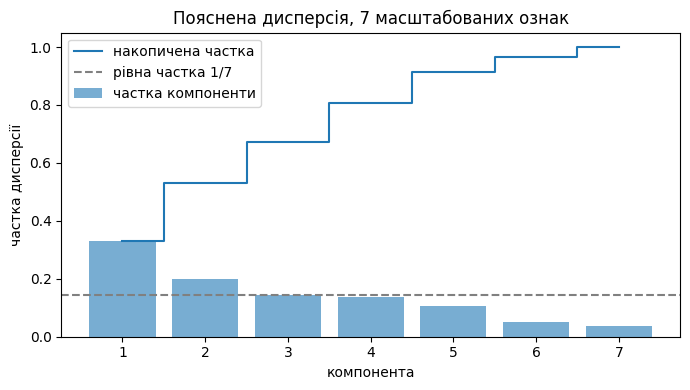

In [14]:
# Усі 7 компонент: що відкинуто, коли беремо 3
import matplotlib.pyplot as plt

pca_all = PCA(random_state=42).fit(X_dr_scaled)
evr_all = pca_all.explained_variance_ratio_
print('частки всіх 7:', evr_all.round(4))
print('накопичено:', np.cumsum(evr_all).round(4))
print('компонент з власним числом > 1:', int((pca_all.explained_variance_ > 1).sum()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, 8), evr_all, alpha=0.6, label='частка компоненти')
ax.step(range(1, 8), np.cumsum(evr_all), where='mid', label='накопичена частка')
ax.axhline(1 / 7, ls='--', c='gray', label='рівна частка 1/7')
ax.set_xlabel('компонента'); ax.set_ylabel('частка дисперсії')
ax.set_title('Пояснена дисперсія, 7 масштабованих ознак')
ax.legend(); plt.tight_layout(); plt.show()

### Завдання 3: Інтерпретація "Loadings"

Продовжуємо інтерпретацію результатів `PCA`і познайомимось з новим поняттям `loadings`, яке допоможе нам знайти звʼязок між головними компонентами і оригінальними ознаками в наборі даних.

Ми зараз побудували візуалізацію кластерів точок даних в просторі трьох головних компонент. Але хочеться знайти звʼязок між головними компонентами і оригінальними ознаками. Для розуміння, які початкові характеристики даних мають найбільший вплив на ці головні компоненти, ми можемо використати атрибут `components_` методу `PCA`.

#### Що таке `pca.components_`?

`pca.components_` — це масив, який містить коефіцієнти (або "ваги"), що показують внесок кожної вихідної ознаки у кожну з головних компонент. Ці коефіцієнти ще називаються **"loading"** або "навантаженнями" компонент.

- **Loadings** (`навантаження`) відображають важливість кожної змінної (ознаки) для відповідної головної компоненти. Вони показують, яким чином змінні поєднуються, щоб утворити нові, зменшені вимірювання.
- Якщо коефіцієнт має високе абсолютне значення (як позитивне, так і негативне), це вказує на те, що відповідна змінна сильно впливає на головну компоненту.

#### Саме завдання
Ваше завдання — обчислити "навантаження" для кожної з головних компонент і інтерпретувати результати.

1. **Обчислення loadings для компонент:**
   Використайте атрибут `components_` об'єкта PCA для створення DataFrame, який відображатиме внесок кожної вихідної ознаки в кожну головну компоненту.

2. **Інтерпретація результатів:**
   Виведіть значення "навантажень" і проаналізуйте, які ознаки найбільше впливають на кожну головну компоненту.

In [15]:
loadings = pd.DataFrame(pca3.components_.T, index=feats, columns=['PC1', 'PC2', 'PC3'])
print(loadings.round(3))
print('\nперевірка: сума квадратів по компоненті =', (loadings ** 2).sum().round(4).tolist())
print('орієнтир рівного внеску 1/sqrt(7) = %.3f' % (1 / np.sqrt(7)))

                     PC1    PC2    PC3
Income             0.590  0.154 -0.023
Recency            0.003  0.069  0.993
NumStorePurchases  0.499  0.368 -0.061
NumDealsPurchases -0.200  0.603 -0.079
days_lifetime     -0.116  0.602  0.007
years_customer     0.198  0.234  0.035
NumWebVisitsMonth -0.558  0.233 -0.035

перевірка: сума квадратів по компоненті = [1.0, 1.0, 1.0]
орієнтир рівного внеску 1/sqrt(7) = 0.378


In [16]:
# Найсильніші ознаки кожної компоненти, за модулем
for pc in ['PC1', 'PC2', 'PC3']:
    top = loadings[pc].abs().sort_values(ascending=False).head(3)
    signs = ['+' if loadings.loc[f, pc] > 0 else '-' for f in top.index]
    print(pc, [f'{s}{f} ({v:.2f})' for f, s, v in zip(top.index, signs, top.values)])

PC1 ['+Income (0.59)', '-NumWebVisitsMonth (0.56)', '+NumStorePurchases (0.50)']
PC2 ['+NumDealsPurchases (0.60)', '+days_lifetime (0.60)', '+NumStorePurchases (0.37)']
PC3 ['+Recency (0.99)', '-NumDealsPurchases (0.08)', '-NumStorePurchases (0.06)']


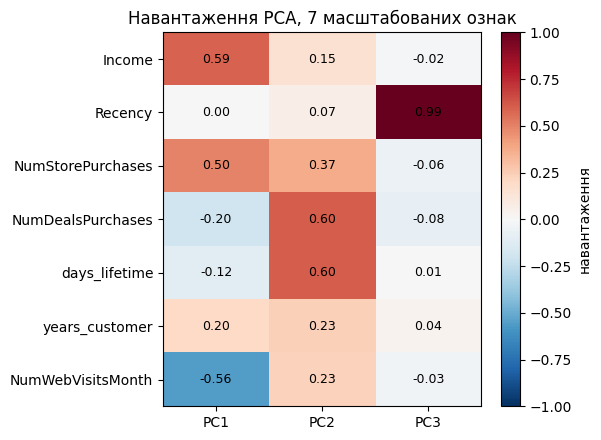

In [17]:
# Теплова карта навантажень, тільки matplotlib
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(loadings.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(3)); ax.set_xticklabels(loadings.columns)
ax.set_yticks(range(len(feats))); ax.set_yticklabels(feats)
for i in range(len(feats)):
    for j in range(3):
        ax.text(j, i, f'{loadings.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='навантаження')
ax.set_title('Навантаження PCA, 7 масштабованих ознак')
plt.tight_layout(); plt.show()

###Завдання 4
Давайте проаналізуємо "навантаження" (**loadings**) для трьох головних компонент після вилучення ознаки `Income`. Це допоможе нам зрозуміти, як змінилася важливість інших ознак для кожної головної компоненти, коли одна з ключових характеристик (`Income`) була вилучена.

#### Кроки для проведення аналізу і ваше завдання:

1. Видаліть ознаку `Income` з нашого набору даних `X` і повторно виконайте PCA (метод головних компонент) для отримання нових "навантажень".

2. Обчисліть нові "навантаження" для трьох головних компонент на наборі даних без `Income`

3. Проаналізуйте, які ознаки мають найбільший вплив на кожну головну компоненту після вилучення `Income`.

4. Перегляньте, наскільки кожна з головних компонент пояснює дисперсію в даних без ознаки `Income`.

In [18]:
feats_no_inc = [f for f in feats if f != 'Income']
X_no_inc = X_clean[feats_no_inc].copy()

scaler_no_inc = StandardScaler()                 # новий скейлер на 6 ознаках
X_no_inc_scaled = scaler_no_inc.fit_transform(X_no_inc)

pca3_no_inc = PCA(n_components=3, random_state=42)
pcs3_no_inc = pca3_no_inc.fit_transform(X_no_inc_scaled)

evr_no_inc = pca3_no_inc.explained_variance_ratio_
print('частки без Income:', evr_no_inc.round(4), ' накопичено:', np.cumsum(evr_no_inc).round(4))
print('частки з Income:  ', evr3.round(4), ' накопичено:', np.cumsum(evr3).round(4))
print('орієнтир 1/6 = %.4f, 1/sqrt(6) = %.3f' % (1 / 6, 1 / np.sqrt(6)))

loadings_no_inc = pd.DataFrame(pca3_no_inc.components_.T, index=feats_no_inc,
                               columns=['PC1', 'PC2', 'PC3'])
print(loadings_no_inc.round(3))

частки без Income: [0.2775 0.2175 0.1666]  накопичено: [0.2775 0.495  0.6616]
частки з Income:   [0.3301 0.199  0.1429]  накопичено: [0.3301 0.5291 0.672 ]
орієнтир 1/6 = 0.1667, 1/sqrt(6) = 0.408
                     PC1    PC2    PC3
Recency            0.010  0.090  0.992
NumStorePurchases -0.394  0.611 -0.077
NumDealsPurchases  0.443  0.459 -0.090
days_lifetime      0.369  0.475  0.020
years_customer    -0.179  0.416 -0.030
NumWebVisitsMonth  0.693 -0.093 -0.020


In [19]:
# Найсильніші ознаки і порівняння з навантаженнями з Income
for pc in ['PC1', 'PC2', 'PC3']:
    top = loadings_no_inc[pc].abs().sort_values(ascending=False).head(3)
    signs = ['+' if loadings_no_inc.loc[f, pc] > 0 else '-' for f in top.index]
    print(pc, [f'{s}{f} ({v:.2f})' for f, s, v in zip(top.index, signs, top.values)])

compare = loadings.drop(index='Income').abs().round(2).join(
    loadings_no_inc.abs().round(2), lsuffix='_з_Income', rsuffix='_без')
print('\nмодулі навантажень, з Income і без:')
print(compare[['PC1_з_Income', 'PC1_без', 'PC2_з_Income', 'PC2_без', 'PC3_з_Income', 'PC3_без']])

PC1 ['+NumWebVisitsMonth (0.69)', '+NumDealsPurchases (0.44)', '-NumStorePurchases (0.39)']
PC2 ['+NumStorePurchases (0.61)', '+days_lifetime (0.48)', '+NumDealsPurchases (0.46)']
PC3 ['+Recency (0.99)', '-NumDealsPurchases (0.09)', '-NumStorePurchases (0.08)']

модулі навантажень, з Income і без:
                   PC1_з_Income  PC1_без  PC2_з_Income  PC2_без  PC3_з_Income  \
Recency                    0.00     0.01          0.07     0.09          0.99   
NumStorePurchases          0.50     0.39          0.37     0.61          0.06   
NumDealsPurchases          0.20     0.44          0.60     0.46          0.08   
days_lifetime              0.12     0.37          0.60     0.48          0.01   
years_customer             0.20     0.18          0.23     0.42          0.04   
NumWebVisitsMonth          0.56     0.69          0.23     0.09          0.03   

                   PC3_без  
Recency               0.99  
NumStorePurchases     0.08  
NumDealsPurchases     0.09  
days_lifetime    

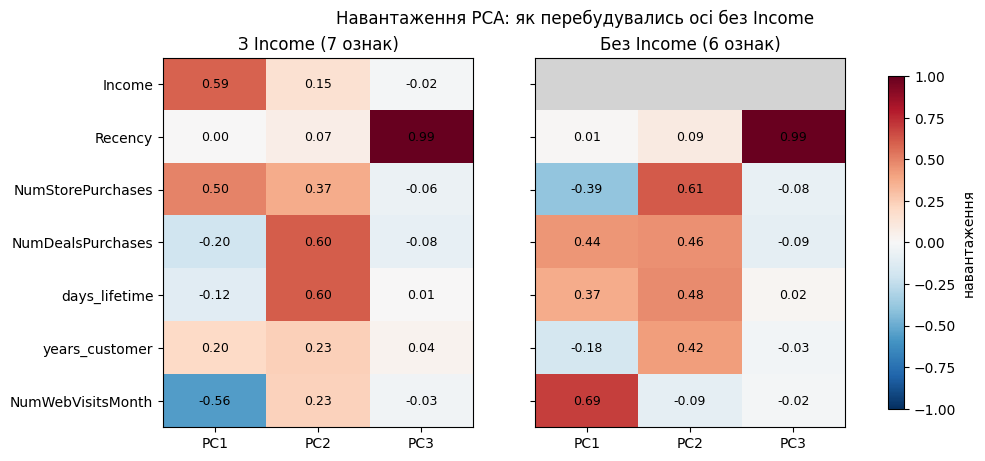

In [20]:
# Теплові карти навантажень: з Income і без, той самий порядок ознак
right = loadings_no_inc.reindex(feats)          # рядок Income стане NaN

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, data, title in zip(axes, [loadings, right],
                           ['З Income (7 ознак)', 'Без Income (6 ознак)']):
    masked = np.ma.masked_invalid(data.values)
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('lightgray')
    im = ax.imshow(masked, cmap=cmap, vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(3)); ax.set_xticklabels(data.columns)
    ax.set_yticks(range(len(feats))); ax.set_yticklabels(feats)
    for i in range(len(feats)):
        for j in range(3):
            v = data.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9)
    ax.set_title(title)

fig.colorbar(im, ax=axes, label='навантаження', shrink=0.9)
fig.suptitle('Навантаження PCA: як перебудувались осі без Income')
plt.show()

Таблиця модулів навантажень показує, що перші дві осі перебудувались повністю: NumDealsPurchases і days_lifetime перейшли з PC2 у PC1, а NumStorePurchases і years_customer з PC1 у PC2. Навантаження з одного набору ознак не переносяться на інший.

### Завдання 5: Візуалізація кластеризації за допомогою t-SNE

Ваше завдання — використати метод t-SNE для візуалізації результатів кластеризації клієнтів у двовимірному просторі. Метод t-SNE допомагає знизити розмірність даних та зберегти локальні структури в даних, що робить його ефективним для візуалізації високорозмірних даних. Ми також зможемо порівняти результат цього методу з РСА.

1. Використайте метод t-SNE для зниження розмірності до 2х вимірів даних, які включають ознаки всі, що і в завданні 1, а також були відмасштабовані перед пониженням розмірностей.

2. Створіть новий DataFrame з координатами, отриманими після застосування t-SNE, та додайте до нього мітки кластерів.

3. Побудуйте інтерактивний 2D-графік розподілу клієнтів, де кольором буде позначено різні кластери і проаналізуйте графік з рекомендаціями нижче (можливо треба буде вивести додаткові візуалізації чи таблиці для інтерпретації, але треба прям зрозуміти, які ознаки формують який кластер і чим кластери відрізняються одне від одного).

  **Опишіть отримані кластери з точки зору ознак.**

4. Опишіть відмінність графіка tSNE від PCA.

#### ЯК можна інтерпретувати з t-SNE?

Хоча t-SNE не надає "компонентів" як РСА, він забезпечує низьковимірне представлення даних, яке можна візуально інтерпретувати:

- **Кластери:** t-SNE особливо добре показує кластери подібних точок. Якщо ви бачите чітко визначені кластери на графіку t-SNE, це свідчить про наявність груп схожих спостережень у ваших даних. Проаналізувати їх можемо, якщо додамо дані в `hover_data` або якщо якісь з даних виведемо як розмір чи форма точок на візуалізації. Також корисно може бути вивести середні значення ознак по кластерам.
- **Локальна структура:** Відносне розташування точок одного кластеру на графіку t-SNE може допомогти вам зрозуміти, які дані подібні між собою.
- **Глобальна структура:** Будьте обережні; t-SNE менш надійний для відображення глобальних структур (наприклад, відстаней між кластерами) у порівнянні з PCA, бо t-SNE націлений на збереження саме локальних структур.

perplexity 5: готово
perplexity 30: готово
perplexity 50: готово


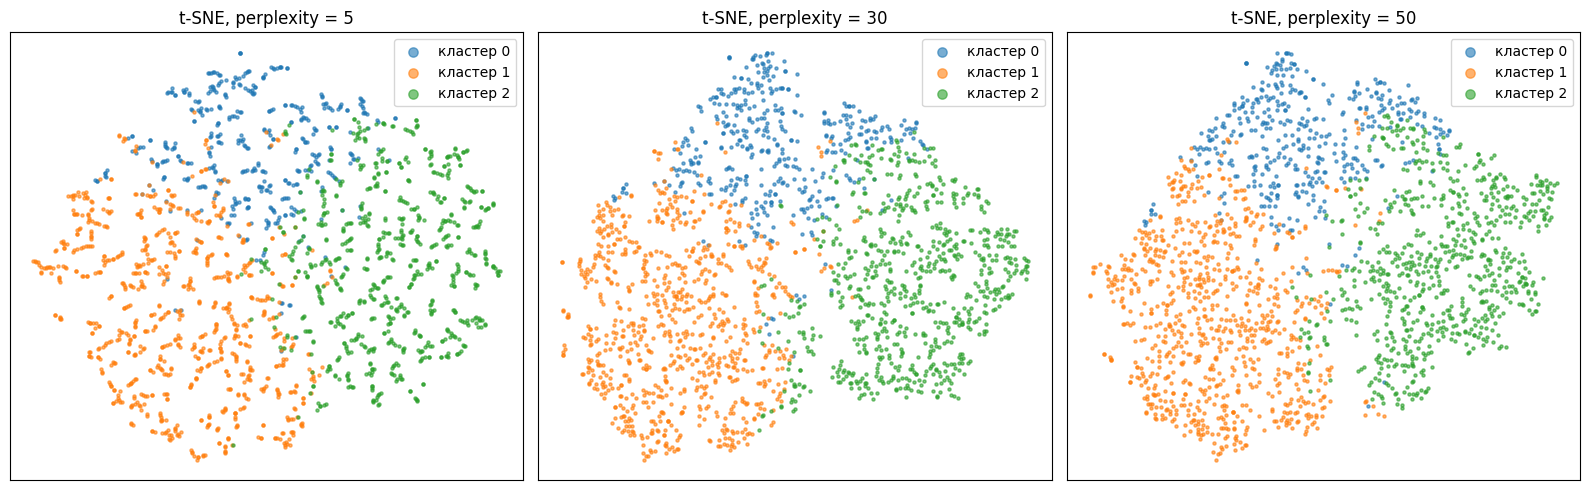

In [21]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# МОЄ РІШЕННЯ: три карти, perplexity 5, 30 і 50. Основна 30 (значення sklearn
# за замовчуванням). Стабільним вважаю лише те, що видно на всіх трьох.
# Вхід: ті самі масштабовані 7 ознак, що в завданні 1. Мітки з KMeans.

tsne_maps = {}

for perp in (5, 30, 50):
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, init='pca')
    tsne_maps[perp] = tsne.fit_transform(X_dr_scaled)
    print(f'perplexity {perp}: готово')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, perp in zip(axes, (5, 30, 50)):
    emb = tsne_maps[perp]
    for c in sorted(np.unique(labels_dr)):
        m = labels_dr == c
        ax.scatter(emb[m, 0], emb[m, 1], s=5, alpha=0.6, label=f'кластер {c}')
    ax.set_title(f't-SNE, perplexity = {perp}')
    ax.set_xticks([]); ax.set_yticks([])     # осі t-SNE не мають змісту
    ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

In [22]:
df_tsne = pd.DataFrame(tsne_maps[30], columns=['TSNE1', 'TSNE2'])
df_tsne['cluster'] = labels_dr.astype(str)
df_tsne = pd.concat([df_tsne, X_dr.reset_index(drop=True)], axis=1)

fig = px.scatter(
    df_tsne, x='TSNE1', y='TSNE2', color='cluster',
    hover_data=feats, opacity=0.7, height=600,
    title='KMeans k=3 на карті t-SNE (perplexity 30)',
)
fig.update_traces(marker=dict(size=4))
fig.show()

In [23]:
# МОЄ РІШЕННЯ: медіани і середні поруч. Медіани стійкі до хвостів
# NumDealsPurchases і NumWebVisitsMonth, середні показують різницю там, де медіани однакові

prof_median = X_dr.groupby(labels_dr).median()
prof_median['n'] = np.bincount(labels_dr)
prof_median['share_%'] = (prof_median['n'] / len(labels_dr) * 100).round(1)
print('МЕДІАНИ')
print(prof_median.round(1).to_string())

prof_mean = X_dr.groupby(labels_dr).mean()
print('\nСЕРЕДНІ')
print(prof_mean.round(1).to_string())

МЕДІАНИ
    Income  Recency  NumStorePurchases  NumDealsPurchases  days_lifetime  years_customer  NumWebVisitsMonth    n  share_%
0  53003.5     51.0                6.0                4.0          534.5            48.0                7.0  426     21.1
1  33587.5     48.0                3.0                2.0          291.0            41.0                7.0  850     42.1
2  72025.0     50.0                8.0                1.0          292.0            47.0                3.0  743     36.8

СЕРЕДНІ
    Income  Recency  NumStorePurchases  NumDealsPurchases  days_lifetime  years_customer  NumWebVisitsMonth
0  51873.4     50.0                6.7                4.9          506.1            48.4                6.9
1  33624.9     48.3                3.1                1.8          307.6            41.6                6.5
2  72169.2     48.9                8.4                1.4          315.4            47.3                3.1


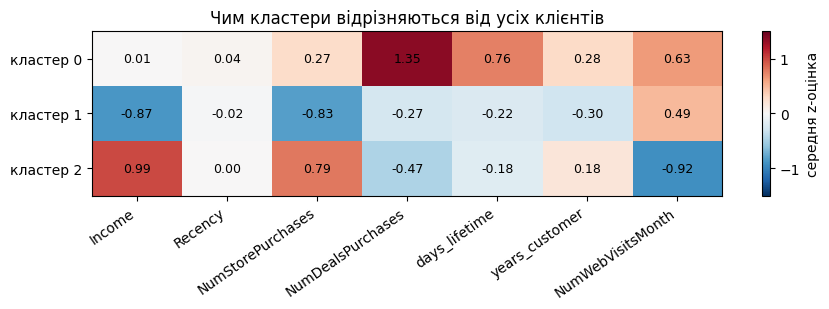

In [24]:
# Середня z-оцінка: на скільки sd кластер відрізняється від усіх клієнтів.
# Одна шкала для всіх ознак, тож видно, яка ознака формує кластер

z_means = pd.DataFrame(X_dr_scaled, columns=feats).groupby(labels_dr).mean()

fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(z_means.values, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_xticks(range(len(feats))); ax.set_xticklabels(feats, rotation=35, ha='right')
ax.set_yticks(range(len(z_means))); ax.set_yticklabels([f'кластер {c}' for c in z_means.index])
for i in range(z_means.shape[0]):
    for j in range(z_means.shape[1]):
        ax.text(j, i, f'{z_means.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='середня z-оцінка')
ax.set_title('Чим кластери відрізняються від усіх клієнтів')
plt.tight_layout(); plt.show()

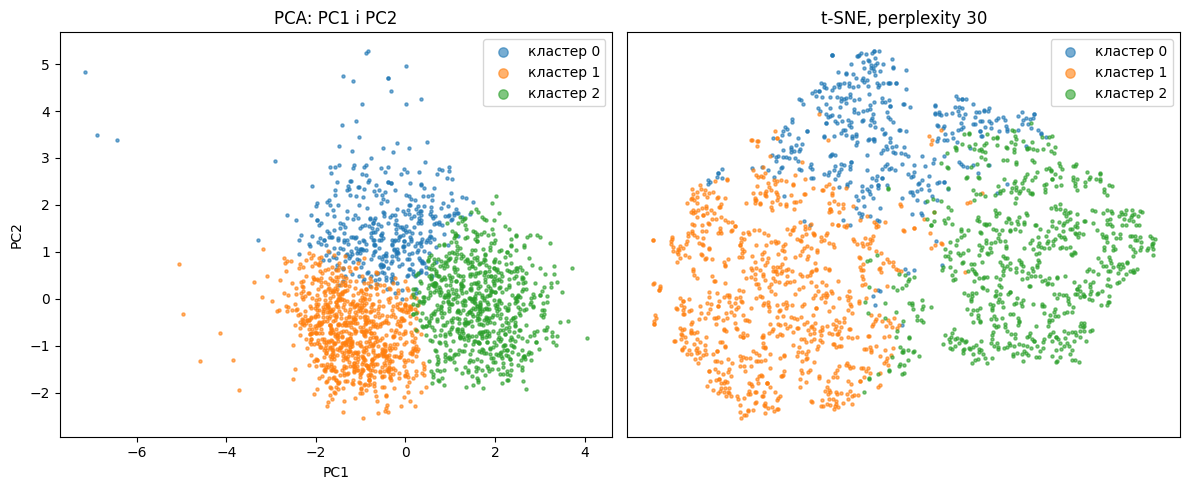

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, emb, title in [(axes[0], pcs3[:, :2], 'PCA: PC1 і PC2'),
                       (axes[1], tsne_maps[30], 't-SNE, perplexity 30')]:
    for c in sorted(np.unique(labels_dr)):
        m = labels_dr == c
        ax.scatter(emb[m, 0], emb[m, 1], s=5, alpha=0.6, label=f'кластер {c}')
    ax.set_title(title); ax.legend(markerscale=3)
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout(); plt.show()

PCA потрібно читати через навантаження: без них головна компонента це
безіменна вісь, а з ними видно, що перша компонента тут означає дохід і
покупки в магазині проти візитів на сайт, друга означає стаж і знижки, а
третя це одна ознака, давність покупки, яка ні з чим не пов'язана.

Навантаження не переносяться між наборами ознак: без доходу обидві перші
осі перебудувались повністю, і вперше помітну роль отримав вік.

Частку компоненти треба порівнювати з рівною часткою, а не з попереднім
числом, бо зі зміною кількості ознак змінюється і сам орієнтир.
t-SNE я запускала з трьома значеннями perplexity і вважала справжнім лише
те, що видно на всіх картах; t-SNE добре показує розташування груп, але
ховає викиди, які PCA показує.